In [75]:
import os
import random
import time
from IPython.display import display
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score
)

print("PyTorch version:", torch.__version__)
print("Available GPUs:", torch.cuda.device_count())


PyTorch version: 2.14.0+cu130
Available GPUs: 1


In [76]:
import torchvision

print("Torchvision version:", torchvision.__version__)


Torchvision version: 0.29.1+cpu


In [77]:
# Load the TF-Flowers dataset
from torchvision import datasets, transforms
from torchvision.datasets.utils import download_and_extract_archive
from torchvision.transforms import InterpolationMode
from itertools import islice

data_dir = "data/flower_photos"

ds_raw = datasets.ImageFolder(data_dir)

# Get the class names
class_names = ["dandelion", "daisy", "tulips", "sunflowers", "roses"]
ds_raw.target_transform = lambda label: class_names.index(ds_raw.classes[label])

print("Dataset loaded successfully!")
print("Number of images:", len(ds_raw))
print("Number of classes:", len(class_names))
print("Class names:", class_names)


Dataset loaded successfully!
Number of images: 3670
Number of classes: 5
Class names: ['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']


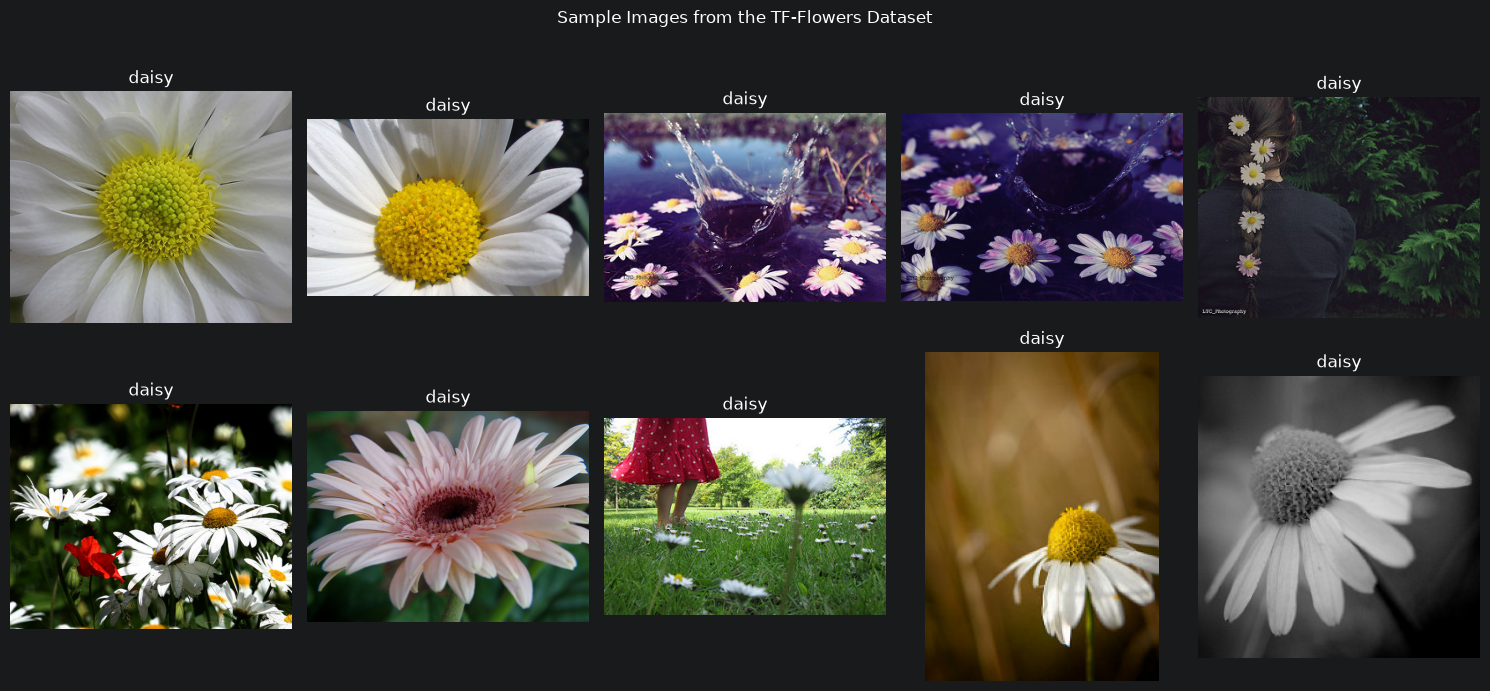

In [78]:

# Display 10 sample images
fig, axes = plt.subplots(2, 5, figsize=(15, 7))

for i, (image, label) in enumerate(
    islice(ds_raw, 10)
):
    row = i // 5
    col = i % 5

    axes[row, col].imshow(image)
    axes[row, col].set_title(class_names[label])
    axes[row, col].axis("off")

plt.suptitle("Sample Images from the TF-Flowers Dataset")
plt.tight_layout()
plt.show()


In [79]:
# Inspect the dimensions of the first image
for image, label in islice(ds_raw, 1):
    image = np.array(image)
    print("Image shape:", image.shape)
    print("Image data type:", image.dtype)
    print("Minimum pixel value:", image.min())
    print("Maximum pixel value:", image.max())


Image shape: (263, 320, 3)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 238


In [80]:
# Step 4: Resize all images to 64 x 64

IMAGE_SIZE = (64, 64)

images = []
labels = []

for image, label in ds_raw:

    # Resize the image
    image = transforms.functional.resize(
        transforms.functional.pil_to_tensor(image).float(),
        IMAGE_SIZE,
        interpolation=InterpolationMode.BILINEAR,
        antialias=True
    )

    # Convert to uint8
    image = image.permute(1, 2, 0).byte().numpy()

    images.append(image)
    labels.append(int(label))

# Convert lists to NumPy arrays
X = np.stack(images)
y = np.array(labels, dtype=np.int64)

print("Images shape:", X.shape)
print("Labels shape:", y.shape)
print("Image data type:", X.dtype)
print("Minimum pixel value:", X.min())
print("Maximum pixel value:", X.max())


Images shape: (3670, 64, 64, 3)
Labels shape: (3670,)
Image data type: uint8
Minimum pixel value: 0
Maximum pixel value: 255


In [81]:
# Step 5: Split the dataset into 70%, 15%, and 15%

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide the remaining 30% equally
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training images:", len(X_train))
print("Validation images:", len(X_val))
print("Testing images:", len(X_test))

print("\nTotal images:", len(X_train) + len(X_val) + len(X_test))

Training images: 2569
Validation images: 550
Testing images: 551

Total images: 3670


In [82]:
# Check how many images from each class are in each subset

class_summary = pd.DataFrame({
    "Class": class_names,
    "Training": [
        np.sum(y_train == i) for i in range(len(class_names))
    ],
    "Validation": [
        np.sum(y_val == i) for i in range(len(class_names))
    ],
    "Testing": [
        np.sum(y_test == i) for i in range(len(class_names))
    ]
})

display(class_summary)

,Class,Training,Validation,Testing
0,dandelion,629,134,135
1,daisy,443,95,95
2,tulips,559,120,120
3,sunflowers,489,105,105
4,roses,449,96,96


In [83]:
# Step 6: Normalize the images to the range [0, 1]

X_train_norm = X_train.astype("float32") / 255.0
X_val_norm = X_val.astype("float32") / 255.0
X_test_norm = X_test.astype("float32") / 255.0

print("Training data shape:", X_train_norm.shape)
print("Validation data shape:", X_val_norm.shape)
print("Testing data shape:", X_test_norm.shape)

print("\nTraining pixel range:")
print("Minimum:", X_train_norm.min())
print("Maximum:", X_train_norm.max())

print("\nData type:", X_train_norm.dtype)

Training data shape: (2569, 64, 64, 3)
Validation data shape: (550, 64, 64, 3)
Testing data shape: (551, 64, 64, 3)

Training pixel range:
Minimum: 0.0
Maximum: 1.0

Data type: float32


## Model A

In [84]:

# Step 7: Build Model A - Standard CNN

model_a = nn.Sequential(

    # Initial standard convolution
    nn.Conv2d(
        3, 16, kernel_size=3,
        padding="same"
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Standard convolution block 1
    nn.Conv2d(16, 32, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Standard convolution block 2
    nn.Conv2d(32, 64, kernel_size=3, padding="same"),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Standard convolution block 3
    nn.Conv2d(64, 128, kernel_size=3, padding="same"),
    nn.ReLU(),

    # Compact classification head
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(128, 32),
    nn.ReLU(),
    nn.Linear(32, len(class_names))
)

# Display the architecture
print(model_a)

# Calculate trainable parameters
trainable_params_a = sum(p.numel() for p in model_a.parameters() if p.requires_grad)

print("\nModel A trainable parameters:", trainable_params_a)


Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (4): ReLU()
  (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (6): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (7): ReLU()
  (8): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (10): ReLU()
  (11): AdaptiveAvgPool2d(output_size=1)
  (12): Flatten(start_dim=1, end_dim=-1)
  (13): Linear(in_features=128, out_features=32, bias=True)
  (14): ReLU()
  (15): Linear(in_features=32, out_features=5, bias=True)
)

Model A trainable parameters: 101733


## Model B

In [85]:

# Step 8: Build Model B - Lightweight CNN

model_b = nn.Sequential(

    # Initial standard convolution
    nn.Conv2d(
        3, 16, kernel_size=3,
        padding="same"
    ),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Depthwise separable convolution block 1
    nn.Conv2d(16, 16, kernel_size=3, padding="same", groups=16, bias=False),
    nn.Conv2d(16, 32, kernel_size=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Depthwise separable convolution block 2
    nn.Conv2d(32, 32, kernel_size=3, padding="same", groups=32, bias=False),
    nn.Conv2d(32, 64, kernel_size=1),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    # Depthwise separable convolution block 3
    nn.Conv2d(64, 64, kernel_size=3, padding="same", groups=64, bias=False),
    nn.Conv2d(64, 128, kernel_size=1),
    nn.ReLU(),

    # Compact classification head
    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(128, 32),
    nn.ReLU(),
    nn.Linear(32, len(class_names))
)

# Display the architecture
print(model_b)

# Verify the assignment's parameter constraint
trainable_params_b = sum(p.numel() for p in model_b.parameters() if p.requires_grad)

print("\nModel B trainable parameters:", trainable_params_b)
print("Meets fewer-than-100,000 requirement:",
      trainable_params_b < 100_000)

assert trainable_params_b < 100_000, \
    "Model B exceeds the 100,000-parameter limit!"


Sequential(
  (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=same)
  (1): ReLU()
  (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (3): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=same, groups=16, bias=False)
  (4): Conv2d(16, 32, kernel_size=(1, 1), stride=(1, 1))
  (5): ReLU()
  (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (7): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=same, groups=32, bias=False)
  (8): Conv2d(32, 64, kernel_size=(1, 1), stride=(1, 1))
  (9): ReLU()
  (10): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=same, groups=64, bias=False)
  (12): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1))
  (13): ReLU()
  (14): AdaptiveAvgPool2d(output_size=1)
  (15): Flatten(start_dim=1, end_dim=-1)
  (16): Linear(in_features=128, out_features=32, bias=True)
  (17): ReLU()
 

In [86]:
# Step 9: Configure Model A with Adam

from torch.utils.data import TensorDataset, DataLoader
from types import SimpleNamespace
import copy

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
criterion = nn.CrossEntropyLoss()

train_dataset = TensorDataset(
    torch.from_numpy(X_train_norm).permute(0, 3, 1, 2).contiguous(),
    torch.from_numpy(y_train)
)
val_dataset = TensorDataset(
    torch.from_numpy(X_val_norm).permute(0, 3, 1, 2).contiguous(),
    torch.from_numpy(y_val)
)

def train_model(model, optimizer, epochs, batch_size=32, verbose=1):
    model.to(device)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_dataset, batch_size=batch_size)
    metrics = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}

    for epoch in range(epochs):
        model.train()
        train_loss, train_correct = 0.0, 0

        for inputs, targets in train_loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, targets)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * targets.size(0)
            train_correct += (outputs.argmax(dim=1) == targets).sum().item()

        model.eval()
        val_loss, val_correct = 0.0, 0
        with torch.no_grad():
            for inputs, targets in val_loader:
                inputs, targets = inputs.to(device), targets.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, targets)
                val_loss += loss.item() * targets.size(0)
                val_correct += (outputs.argmax(dim=1) == targets).sum().item()

        metrics["loss"].append(train_loss / len(train_dataset))
        metrics["accuracy"].append(train_correct / len(train_dataset))
        metrics["val_loss"].append(val_loss / len(val_dataset))
        metrics["val_accuracy"].append(val_correct / len(val_dataset))

        if verbose:
            print(f"Epoch {epoch + 1}/{epochs} - "
                  f"loss: {metrics['loss'][-1]:.4f} - "
                  f"accuracy: {metrics['accuracy'][-1]:.4f} - "
                  f"val_loss: {metrics['val_loss'][-1]:.4f} - "
                  f"val_accuracy: {metrics['val_accuracy'][-1]:.4f}")

    return SimpleNamespace(history=metrics)

def fresh_model(model):
    cloned = copy.deepcopy(model)
    for layer in cloned.modules():
        if hasattr(layer, "reset_parameters"):
            layer.reset_parameters()
    return cloned.to(device)

def predict_probabilities(model, X, batch_size=32):
    model.eval()
    batches = DataLoader(
        torch.from_numpy(X).permute(0, 3, 1, 2).contiguous(),
        batch_size=batch_size
    )
    probabilities = []
    with torch.no_grad():
        for inputs in batches:
            outputs = model(inputs.to(device))
            probabilities.append(torch.softmax(outputs, dim=1).cpu().numpy())
    return np.concatenate(probabilities, axis=0)

model_a.to(device)
optimizer_a = optim.Adam(model_a.parameters(), lr=0.001)

print("Model A compiled successfully.")
print("Optimizer: Adam")
print("Learning rate: 0.001")
print("Loss function: Sparse categorical cross-entropy")


Model A compiled successfully.
Optimizer: Adam
Learning rate: 0.001
Loss function: Sparse categorical cross-entropy


In [87]:
# Step 10: Preliminary optimizer comparison

optimizers = {
    "SGD": lambda params: optim.SGD(params, lr=0.01),
    "SGD with Momentum": lambda params: optim.SGD(
        params,
        lr=0.01,
        momentum=0.9
    ),
    "Adam": lambda params: optim.Adam(params, lr=0.001)
}

optimizer_results = []

for optimizer_name, optimizer_factory in optimizers.items():

    print(f"\nTraining Model A with {optimizer_name}...")

    # Create a fresh model so each optimizer starts from the same
    # initial weights.
    model = copy.deepcopy(model_a)
    model.load_state_dict(model_a.state_dict())
    optimizer = optimizer_factory(model.parameters())

    start_time = time.time()

    history = train_model(
        model,
        optimizer,
        epochs=5,
        batch_size=32,
        verbose=1
    )

    elapsed_time = time.time() - start_time

    optimizer_results.append({
        "Optimizer": optimizer_name,
        "Final Training Accuracy": history.history["accuracy"][-1],
        "Final Validation Accuracy": history.history["val_accuracy"][-1],
        "Final Training Loss": history.history["loss"][-1],
        "Final Validation Loss": history.history["val_loss"][-1],
        "Total Training Time (s)": elapsed_time,
        "Average Time per Epoch (s)": elapsed_time / 5
    })

optimizer_df = pd.DataFrame(optimizer_results)

print("\nOptimizer Comparison Results:")
display(optimizer_df.round(4))



Training Model A with SGD...
Epoch 1/5 - loss: 1.6050 - accuracy: 0.2176 - val_loss: 1.6036 - val_accuracy: 0.2182
Epoch 2/5 - loss: 1.6031 - accuracy: 0.2176 - val_loss: 1.6024 - val_accuracy: 0.2182
Epoch 3/5 - loss: 1.6021 - accuracy: 0.2176 - val_loss: 1.6015 - val_accuracy: 0.2182
Epoch 4/5 - loss: 1.6013 - accuracy: 0.2176 - val_loss: 1.6009 - val_accuracy: 0.2436
Epoch 5/5 - loss: 1.6007 - accuracy: 0.2452 - val_loss: 1.6005 - val_accuracy: 0.2436

Training Model A with SGD with Momentum...
Epoch 1/5 - loss: 1.6030 - accuracy: 0.2301 - val_loss: 1.6002 - val_accuracy: 0.2436
Epoch 2/5 - loss: 1.6006 - accuracy: 0.2448 - val_loss: 1.5995 - val_accuracy: 0.2436
Epoch 3/5 - loss: 1.6002 - accuracy: 0.2448 - val_loss: 1.5988 - val_accuracy: 0.2436
Epoch 4/5 - loss: 1.5993 - accuracy: 0.2448 - val_loss: 1.5973 - val_accuracy: 0.2436
Epoch 5/5 - loss: 1.5966 - accuracy: 0.2448 - val_loss: 1.5946 - val_accuracy: 0.2436

Training Model A with Adam...
Epoch 1/5 - loss: 1.5129 - accuracy

,Optimizer,Final Training Accuracy,Final Validation Accuracy,Final Training Loss,Final Validation Loss,Total Training Time (s),Average Time per Epoch (s)
0,SGD,0.2452,0.2436,1.6007,1.6005,4.5132,0.9026
1,SGD with Momentum,0.2448,0.2436,1.5966,1.5946,4.4529,0.8906
2,Adam,0.5547,0.6000,1.0886,1.0263,4.7687,0.9537


In [88]:
# Step 11: Train Model A for 20 epochs

# Create a fresh Model A
model_a_final = fresh_model(model_a)

# Compile using the selected optimizer
optimizer_a_final = optim.Adam(model_a_final.parameters(), lr=0.001)

# Measure training time
start_time = time.time()

history_a = train_model(
    model_a_final,
    optimizer_a_final,
    epochs=70,
    batch_size=32,
    verbose=1
)

time_a = time.time() - start_time

print(f"\nModel A total training time: {time_a:.2f} seconds")
print(f"Average time per epoch: {time_a / 20:.2f} seconds")


Epoch 1/70 - loss: 1.5591 - accuracy: 0.2694 - val_loss: 1.4678 - val_accuracy: 0.3436
Epoch 2/70 - loss: 1.4383 - accuracy: 0.3375 - val_loss: 1.3700 - val_accuracy: 0.3891
Epoch 3/70 - loss: 1.3813 - accuracy: 0.3889 - val_loss: 1.3340 - val_accuracy: 0.4127
Epoch 4/70 - loss: 1.3338 - accuracy: 0.4181 - val_loss: 1.3158 - val_accuracy: 0.4618
Epoch 5/70 - loss: 1.2100 - accuracy: 0.4909 - val_loss: 1.0362 - val_accuracy: 0.5818
Epoch 6/70 - loss: 1.0588 - accuracy: 0.5671 - val_loss: 0.9824 - val_accuracy: 0.6091
Epoch 7/70 - loss: 1.0225 - accuracy: 0.5862 - val_loss: 1.0107 - val_accuracy: 0.5873
Epoch 8/70 - loss: 0.9777 - accuracy: 0.5995 - val_loss: 1.0120 - val_accuracy: 0.5673
Epoch 9/70 - loss: 0.9565 - accuracy: 0.6150 - val_loss: 0.9487 - val_accuracy: 0.5964
Epoch 10/70 - loss: 0.9293 - accuracy: 0.6213 - val_loss: 0.9473 - val_accuracy: 0.6218
Epoch 11/70 - loss: 0.9124 - accuracy: 0.6228 - val_loss: 0.8929 - val_accuracy: 0.6218
Epoch 12/70 - loss: 0.8924 - accuracy: 0.

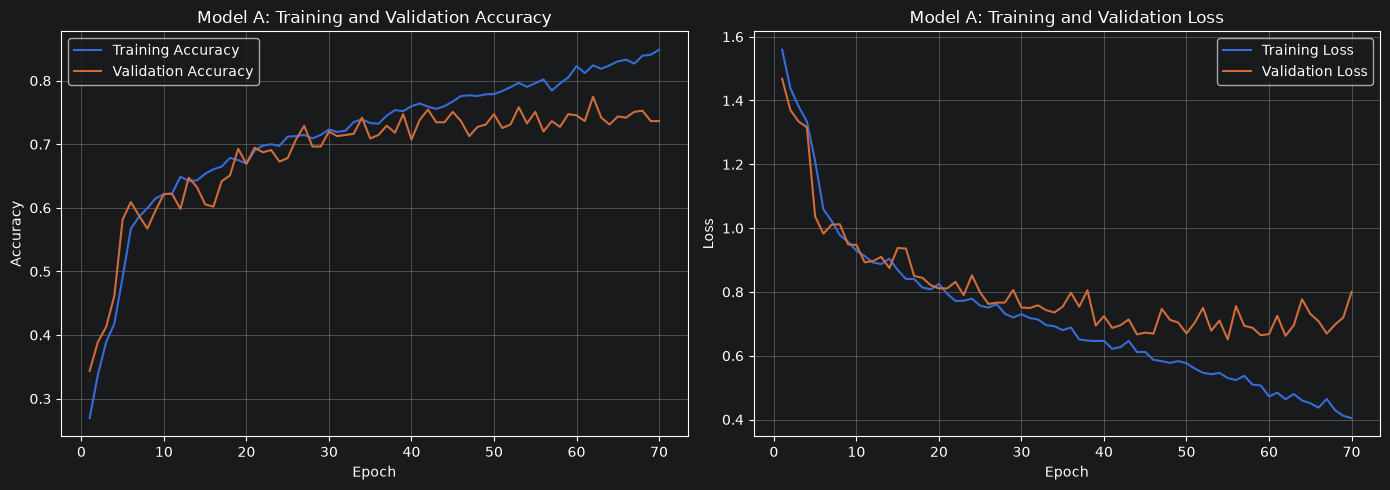

In [89]:
# Step 12: Plot Model A training history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history_a.history["loss"]) + 1)

# Accuracy curves
axes[0].plot(
    epochs_range,
    history_a.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    epochs_range,
    history_a.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Model A: Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss curves
axes[1].plot(
    epochs_range,
    history_a.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    epochs_range,
    history_a.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Model A: Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [90]:
# Step 13: Train Model B for 20 epochs

# Create a fresh Model B
model_b_final = fresh_model(model_b)

# Compile with the same optimizer and loss
optimizer_b_final = optim.Adam(model_b_final.parameters(), lr=0.001)

# Measure training time
start_time = time.time()

history_b = train_model(
    model_b_final,
    optimizer_b_final,
    epochs=80,
    batch_size=32,
    verbose=1
)

time_b = time.time() - start_time

print(f"\nModel B total training time: {time_b:.2f} seconds")
print(f"Average time per epoch: {time_b / 20:.2f} seconds")


Epoch 1/80 - loss: 1.6048 - accuracy: 0.2207 - val_loss: 1.6004 - val_accuracy: 0.2436
Epoch 2/80 - loss: 1.5768 - accuracy: 0.2631 - val_loss: 1.4450 - val_accuracy: 0.3236
Epoch 3/80 - loss: 1.3999 - accuracy: 0.3686 - val_loss: 1.3323 - val_accuracy: 0.3927
Epoch 4/80 - loss: 1.3475 - accuracy: 0.3811 - val_loss: 1.3154 - val_accuracy: 0.3745
Epoch 5/80 - loss: 1.3254 - accuracy: 0.3873 - val_loss: 1.3009 - val_accuracy: 0.3927
Epoch 6/80 - loss: 1.3141 - accuracy: 0.3978 - val_loss: 1.2797 - val_accuracy: 0.4255
Epoch 7/80 - loss: 1.3017 - accuracy: 0.4336 - val_loss: 1.2727 - val_accuracy: 0.4382
Epoch 8/80 - loss: 1.2503 - accuracy: 0.4656 - val_loss: 1.2106 - val_accuracy: 0.4727
Epoch 9/80 - loss: 1.2086 - accuracy: 0.4729 - val_loss: 1.2238 - val_accuracy: 0.4291
Epoch 10/80 - loss: 1.1974 - accuracy: 0.4858 - val_loss: 1.1346 - val_accuracy: 0.5164
Epoch 11/80 - loss: 1.1561 - accuracy: 0.5189 - val_loss: 1.1407 - val_accuracy: 0.5055
Epoch 12/80 - loss: 1.1371 - accuracy: 0.

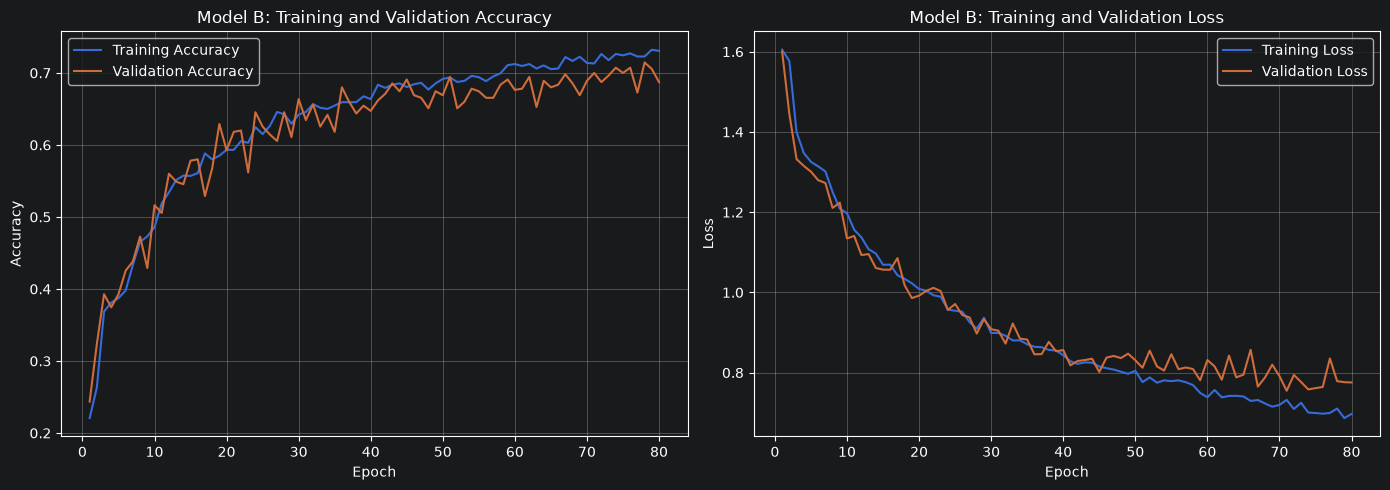

In [91]:
# Step 15: Plot Model B training history

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

epochs_range = range(1, len(history_b.history["loss"]) + 1)

# Accuracy curves
axes[0].plot(
    epochs_range,
    history_b.history["accuracy"],
    label="Training Accuracy"
)
axes[0].plot(
    epochs_range,
    history_b.history["val_accuracy"],
    label="Validation Accuracy"
)
axes[0].set_title("Model B: Training and Validation Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True)

# Loss curves
axes[1].plot(
    epochs_range,
    history_b.history["loss"],
    label="Training Loss"
)
axes[1].plot(
    epochs_range,
    history_b.history["val_loss"],
    label="Validation Loss"
)
axes[1].set_title("Model B: Training and Validation Loss")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()


Model A - Standard CNN
Test accuracy: 0.7223
Macro precision: 0.7418
Macro recall: 0.7133

Classification Report:
              precision    recall  f1-score   support

   dandelion       0.67      0.86      0.75       135
       daisy       0.94      0.63      0.75        95
      tulips       0.72      0.61      0.66       120
  sunflowers       0.75      0.90      0.82       105
       roses       0.63      0.56      0.59        96

    accuracy                           0.72       551
   macro avg       0.74      0.71      0.72       551
weighted avg       0.74      0.72      0.72       551



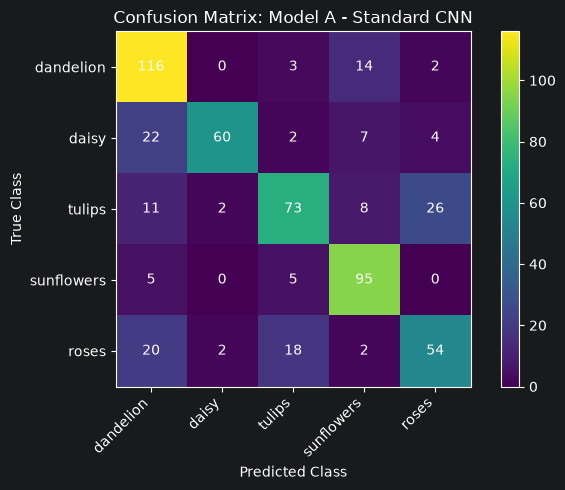


Model B - Lightweight CNN
Test accuracy: 0.6987
Macro precision: 0.7146
Macro recall: 0.6900

Classification Report:
              precision    recall  f1-score   support

   dandelion       0.64      0.88      0.74       135
       daisy       0.86      0.77      0.81        95
      tulips       0.65      0.58      0.62       120
  sunflowers       0.84      0.69      0.75       105
       roses       0.58      0.53      0.55        96

    accuracy                           0.70       551
   macro avg       0.71      0.69      0.70       551
weighted avg       0.71      0.70      0.70       551



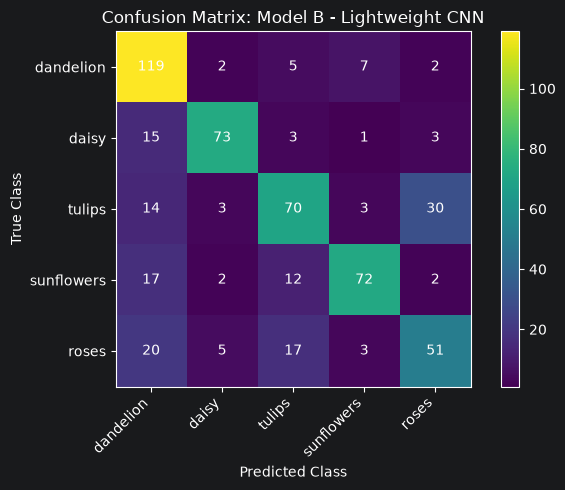


Custom CNN Test Results:


,Accuracy,Macro Precision,Macro Recall
Model A - Standard CNN,0.7223,0.7418,0.7133
Model B - Lightweight CNN,0.6987,0.7146,0.6900


In [92]:
# Step 16: Evaluate both custom CNN models

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_score,
    recall_score
)

custom_models = {
    "Model A - Standard CNN": model_a_final,
    "Model B - Lightweight CNN": model_b_final
}

test_results = {}

for model_name, model in custom_models.items():

    print(f"\n{'=' * 60}")
    print(model_name)
    print("=" * 60)

    # Predict probabilities for the test images
    y_prob = predict_probabilities(model, X_test_norm)

    # Convert probabilities into predicted class labels
    y_pred = np.argmax(y_prob, axis=1)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="macro", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="macro", zero_division=0
    )

    test_results[model_name] = {
        "Accuracy": accuracy,
        "Macro Precision": precision,
        "Macro Recall": recall
    }

    print(f"Test accuracy: {accuracy:.4f}")
    print(f"Macro precision: {precision:.4f}")
    print(f"Macro recall: {recall:.4f}")

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        zero_division=0
    ))

    # Plot the confusion matrix
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=np.arange(len(class_names))
    )

    plt.figure(figsize=(7, 5))
    plt.imshow(cm)
    plt.title(f"Confusion Matrix: {model_name}")
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")
    plt.xticks(
        np.arange(len(class_names)),
        class_names,
        rotation=45,
        ha="right"
    )
    plt.yticks(np.arange(len(class_names)), class_names)
    plt.colorbar()

    for i in range(len(class_names)):
        for j in range(len(class_names)):
            plt.text(j, i, cm[i, j], ha="center", va="center")

    plt.tight_layout()
    plt.show()

# Summary table
test_results_df = pd.DataFrame(test_results).T
print("\nCustom CNN Test Results:")
display(test_results_df.round(4))


In [93]:
# Step 18: Summarize custom CNN performance

custom_summary = pd.DataFrame([
    {
        "Model": "Model A - Standard CNN",
        "Trainable Parameters": sum(p.numel() for p in model_a_final.parameters() if p.requires_grad),
        "Training Time (s)": time_a,
        "Average Time per Epoch (s)": time_a / 20,
        "Final Training Accuracy": history_a.history["accuracy"][-1],
        "Final Validation Accuracy": history_a.history["val_accuracy"][-1],
        "Test Accuracy": test_results[
            "Model A - Standard CNN"
        ]["Accuracy"],
        "Macro Precision": test_results[
            "Model A - Standard CNN"
        ]["Macro Precision"],
        "Macro Recall": test_results[
            "Model A - Standard CNN"
        ]["Macro Recall"]
    },
    {
        "Model": "Model B - Lightweight CNN",
        "Trainable Parameters": sum(p.numel() for p in model_b_final.parameters() if p.requires_grad),
        "Training Time (s)": time_b,
        "Average Time per Epoch (s)": time_b / 20,
        "Final Training Accuracy": history_b.history["accuracy"][-1],
        "Final Validation Accuracy": history_b.history["val_accuracy"][-1],
        "Test Accuracy": test_results[
            "Model B - Lightweight CNN"
        ]["Accuracy"],
        "Macro Precision": test_results[
            "Model B - Lightweight CNN"
        ]["Macro Precision"],
        "Macro Recall": test_results[
            "Model B - Lightweight CNN"
        ]["Macro Recall"]
    }
])

display(custom_summary.round(4))


,Model,Trainable Parameters,Training Time (s),Average Time per Epoch (s),Final Training Accuracy,Final Validation Accuracy,Test Accuracy,Macro Precision,Macro Recall
0,Model A - Standard CNN,101733,59.9647,2.9982,0.8486,0.7364,0.7223,0.7418,0.7133
1,Model B - Lightweight CNN,16725,25.5486,1.2774,0.7306,0.6873,0.6987,0.7146,0.6900


In [94]:
# Step 19: Check pretrained model availability

from torchvision.models import mobilenet_v2, efficientnet_b0

print("MobileNetV2 is available.")
print("EfficientNetB0 is available.")


MobileNetV2 is available.
EfficientNetB0 is available.
